# Econ 4850 · Economic Analysis with Python
## Lecture 3b: Numerical Methods
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- How the bisection algorithm and Newton's method find roots, and the trade-offs between them.
- How to obtain derivatives analytically, by finite differences, or by automatic differentiation.
- How to solve unconstrained and constrained optimization problems with `scipy.optimize`, and why the choice of algorithm matters.
- The difference between local and global minimization.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as opt

## Computing Solutions Numerically: SciPy

- So far, everything we have computed has a closed form.

- This, however, limits the analysis we can do.

- In economics, as in any science, we need numerical solutions everywhere. For example, we often have to find the root of a system of first-order conditions (FOCs), and in applications the root seldom has a closed form.
    - We will introduce two fundamental algorithms.

- Another important use of SciPy is finding extrema, e.g., solving a constrained maximization problem or estimating a model by minimizing the distance between model moments and empirical moments.

- `scipy.optimize` is a perfect package for an introduction.

- We will discuss 1. root finding and 2. minimization.

## Root Finding

- Root finding is at the heart of many economic analyses, because so many core concepts (market equilibrium, steady-state growth, break-even points, or implied volatility in finance) can be reformulated as finding a solution $x^*$ to an equation $f(x^*)=0$.
    - Writing the condition as $f(x^*)=0$ is without loss of generality (WLOG). Why?

- In other words, you are searching for the values of a set of endogenous variables (price, growth rate, interest rate, etc.) that satisfy a particular condition.

- Those conditions can be a set of FOCs or market-clearing conditions.

- The solution $x$ can even be a function.

- We will discuss two fundamental algorithms.

### The bisection algorithm: a simple and powerful tool

- Bisection is a robust method that relies on a key result from mathematics: the Intermediate Value Theorem.
    - If $f$ is continuous and $f(a)f(b) < 0$, a root exists in $[a, b]$ (intermediate value theorem), and bisection is guaranteed to find one; if $f$ is also monotone, that root is unique.

- Let's see how the algorithm works.

**Algorithm**

1. Start with an interval $[a, b]$ where $f(a)f(b) < 0$.
2. Compute the midpoint:
   $$
   c = \frac{a + b}{2}.
   $$
3. Evaluate $f(c)$:
   - If $f(c) = 0$, you have found the root.
   - If $f(c)f(a) < 0$, the root lies in $[a, c]$; set $b = c$.
   - Otherwise, $f(c)f(b) < 0$ and the root lies in $[c, b]$; set $a = c$.
4. Repeat until $|f(c)|$ (or the width of $[a, b]$) is smaller than a desired tolerance, e.g., `tol=1e-6`.

Practice: try to write the function yourself before reading the solution below.

The tolerance cannot be arbitrarily small. Near the root $\sqrt{10}$ of the test function used below, adjacent double-precision numbers are about $4\times10^{-16}$ apart, so $|f(c)|$ cannot fall below roughly $2\times10^{-15}$; a tolerance below machine precision, such as `1e-20`, is never met, so the loop exhausts `max_iter` and raises a `RuntimeError`.

In [2]:
def bisection(f, a, b, tol=1e-6, max_iter=1000):
    if f(a) * f(b) >= 0:
        raise ValueError("The function must change sign over the interval [a, b].")

    for _ in range(max_iter):
        c = (a + b) / 2  # midpoint

        # Stopping rule based on the value f(c)
        # (alternative stopping rule: abs(b - a) < tol)
        if abs(f(c)) < tol:
            return c  # root found
        elif f(c) * f(a) < 0:
            b = c  # root lies in [a, c]
        else:
            a = c  # root lies in [c, b]

    raise RuntimeError("Maximum number of iterations reached without convergence.")

The following bisection function is copied from [Python Programming and Numerical Methods: A Guide for Engineers and Scientists](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter19.03-Bisection-Method.html). Let's compare the speed of the two.

In [3]:
def my_bisection(f, a, b, tol=1e-6):
    # approximates a root, R, of f bounded
    # by a and b to within tolerance
    # | f(m) | < tol with m the midpoint
    # between a and b Recursive implementation

    # check if a and b bound a root
    if np.sign(f(a)) == np.sign(f(b)):
        raise Exception(
            "The scalars a and b do not bound a root")

    # get midpoint
    m = (a + b) / 2

    if np.abs(f(m)) < tol:
        # stopping condition, report m as root
        return m

    elif np.sign(f(a)) == np.sign(f(m)):
        # case where m is an improvement on a.
        # Make recursive call with a = m
        return my_bisection(f, m, b, tol)

    elif np.sign(f(b)) == np.sign(f(m)):
        # case where m is an improvement on b.
        # Make recursive call with b = m
        return my_bisection(f, a, m, tol)

In [4]:
def f_test(x):
    return 10 - x**2


print(bisection(f_test, 2, 10))
print(my_bisection(f_test, 2, 10))

3.1622776985168457
3.1622776985168457


In [5]:
%%timeit
bisection(f_test, 2, 10)

6.45 μs ± 81.6 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [6]:
%%timeit
my_bisection(f_test, 2, 10)

65.1 μs ± 508 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


Our loop-based `bisection` is preferred for two reasons:
1. We can control the maximum number of iterations.
2. It is faster. Most of the gap comes from `my_bisection` calling NumPy functions (`np.sign`, `np.abs`) on single numbers, which carries overhead, and from evaluating `f` more often per step; each recursive call adds further function-call overhead.

### Advantages and disadvantages of the bisection algorithm

**Advantages**
1. **Simplicity**:
   - Easy to implement and understand, requiring only basic arithmetic operations.

2. **Guaranteed convergence**:
   - If the function is continuous on the interval and the sign condition $f(a) \cdot f(b) < 0$ holds, the method is guaranteed to converge to a root.

3. **Stability**:
   - Numerical stability is high because the algorithm does not depend on derivatives or higher-order terms.

4. **Deterministic**:
   - The error bound decreases predictably with each iteration, making it easy to control the precision.

5. **No need for derivatives**:
   - Unlike Newton's method, it does not require derivatives, making it suitable for functions that are not differentiable.

6. **Works for non-smooth functions**:
   - Handles non-smooth or piecewise functions as long as continuity and the sign-change condition are met.

**Disadvantages**
1. **Slow convergence**:
   - Convergence is linear, which makes it significantly slower than methods like Newton's method for well-behaved functions.

2. **Dependent on the initial interval**:
   - Requires a known interval $[a, b]$ over which the function changes sign. Finding such an interval is not always straightforward.

3. **Only finds one root**:
   - Finds only one root at a time and does not work well for functions with multiple roots in the same interval unless the interval is chosen carefully.

4. **Not efficient for high accuracy**:
   - Achieving high precision requires many iterations, especially compared with faster-converging methods.

5. **Ignores derivative information**:
   - Does not use derivative information, which can deliver faster convergence in other methods.

6. **Not suitable for multi-dimensional problems**:
   - We need other methods, such as Newton's method.

### Use cases

- The bisection algorithm is particularly useful when robustness and simplicity matter more than speed, or when derivative information is unavailable or unreliable.

- For large-scale or high-precision problems, however, alternatives such as the Newton–Raphson method may be more efficient.

## Newton's Method

- The examples are adapted from [QuantEcon](https://python.quantecon.org/newton_method.html).

### Introduction

- Newton's method, also called the Newton–Raphson method, is a powerful and widely used iterative method for solving nonlinear equations of the form $f(x) = 0$.

- The method uses the *derivative* of the function to iteratively approximate a root of the equation.

- The core idea is to use the tangent line to $f(x)$ at a point $x_n$ as an approximation to the function itself. The point where this tangent line crosses the $x$-axis is the next approximation, $x_{n+1}$.

- This is rather abstract. To understand Newton's method, we first need Taylor's expansion, which approximates a function.

### Digression: Taylor's expansion

- Analyzing a complicated function can be computationally costly.

- When we care about the local behavior of a function around a particular point, we approximate it with a Taylor expansion, which gives a convenient expression.

- The **Taylor series** of a function $f(x)$ about a point $a$ is

$$
f(x) = f(a) + f'(a)(x - a) + \frac{f''(a)}{2!}(x - a)^2 + \frac{f^{(3)}(a)}{3!}(x - a)^3 + \cdots + \frac{f^{(n)}(a)}{n!}(x - a)^n + \cdots
$$

- Here:
    - $f(a)$ is the value of the function at $x = a$.
    - $f'(a)$, $f''(a)$, $f^{(3)}(a)$, etc., are the derivatives of $f(x)$ evaluated at $x = a$.
    - $(x - a)$ is the distance from the point $a$.
    - $n!$ ($n$ factorial) is the product of all positive integers up to $n$.

- The Taylor polynomial of degree $n$ is the truncated Taylor series:

$$
P_n(x) = f(a) + f'(a)(x - a) + \frac{f''(a)}{2!}(x - a)^2 + \cdots + \frac{f^{(n)}(a)}{n!}(x - a)^n.
$$

- This polynomial approximates $f(x)$ near $x = a$.

- The error between the function $f(x)$ and its Taylor polynomial $P_n(x)$ is called the remainder term $R_n(x)$:

$$
f(x) = P_n(x) + R_n(x).
$$

- As we increase $n$, the remainder $R_n(x)$ becomes smaller near $a$, but the computation becomes more costly.

- This [animation](https://en.wikipedia.org/wiki/Taylor_series#/media/File:Logarithm_GIF.gif) shows Taylor polynomials of increasing degree approximating a function.

### Derivation of Newton's method

1. The tangent line to $f(x)$ at $x_n$ is
   $$y = f(x_n) + f'(x_n)(x - x_n),$$
   where $f'(x_n)$ is the derivative of $f(x)$ at $x_n$. This is the first-order Taylor polynomial of $f$ about $x_n$.

2. Set $y = 0$ to find the root of this tangent line:
   $$
   0 = f(x_n) + f'(x_n)(x - x_n).
   $$

3. Solve for $x$ to get the next approximation:
   $$
   x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.
   $$

- It helps to draw a picture: the tangent line at $x_n$ crosses the horizontal axis at $x_{n+1}$.

### Algorithm

1. Start with an initial guess $x_0$.

2. Update iteratively using
   $$
   x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.
   $$

3. Repeat until $|f(x_n)|$ or $|x_{n+1} - x_n|$ is sufficiently small (the convergence criterion).

- Let's write the code.

In [7]:
# This is from QuantEcon, but all variations are essentially the same.
# Note that the derivative Df is passed in as a function.

def newton(f, Df, x_0, tol=1e-7, max_iter=100_000):
    # f and Df are functions

    # x is the current guess x_n; start from the initial guess
    x = x_0

    # Implement the zero-finding formula
    def q(x):
        # q returns x_{n+1} given x_n
        return x - f(x) / Df(x)

    # Ensure the while loop runs at least once
    error = tol + 1

    # Count iterations
    n = 0
    while error > tol:
        n += 1

        # Check whether we have reached the maximum number of iterations
        if n > max_iter:
            raise RuntimeError('Max iteration reached without convergence')

        # Compute the next guess x_{n+1}
        x_next = q(x)
        # Alternatives: np.abs(x - x_next), or a weighted sum of both criteria
        error = np.abs(f(x_next))

        # Update x_n to x_{n+1}
        x = x_next
        print(f'iteration {n}, error = {error:.5f}')
    return x

### How to get the derivative?

- You can always derive it analytically.

- Before ChatGPT, I used an [online calculator](https://www.derivative-calculator.net/), `SymPy` (a Python package for symbolic computation), and/or Mathematica.

- Now, you can also simply ask ChatGPT.

- A second way is to use a finite-difference method (a numerical derivative), shown below.

- Thanks to the growth of machine learning, automatic differentiation has also become accessible and handy.

- We will come back to automatic differentiation later. For now, let's practice with the Solow growth model.

In [8]:
def finite_difference(f, x, h=1e-5):
    # Central difference: f is a function, x is a scalar, h is the step size
    return (f(x + h) - f(x - h)) / (2 * h)

### Solow growth model

- The Solow growth model (also known as the Solow–Swan model) is a foundational framework in economic growth theory. It explains how growth is driven by the accumulation of capital, labor, and technological progress. This framework changed the way economists study growth.

- Developed by Robert Solow and Trevor Swan in the 1950s, it is widely used to study long-run economic growth.

- The key of the model is captured in one equation, the law of motion for capital:

$$k_{t+1}=g(k_t)\quad \text{where} \quad g(k):=sAk^\alpha+(1-\delta)k.$$

- Here:
    - $k_t$ is the capital stock per worker,
    - $A, \alpha > 0$ are production parameters, with $\alpha < 1$,
    - $s > 0$ is the savings rate, and
    - $\delta \in (0, 1)$ is the rate of depreciation.

- An important feature is that there exists a steady state $k^*>0$ such that $g(k^*)=k^*$.
    - The idea is that while capital accumulation brings growth in the short run, growth from capital accumulation (capital deepening) eventually stops.
    - Long-run growth must come from growth in the production parameters (total factor productivity).

- Now, let's find $k^*$ using Newton's method.

But first, let me introduce `namedtuple` from Python's built-in `collections` module, which keeps the code clean. I use it in all my code.

In [9]:
from collections import namedtuple

SolowParameters = namedtuple("SolowParameters", ('A', 's', 'α', 'δ'))

In [10]:
def create_solow_params(A=2.0, s=0.3, α=0.3, δ=0.4):
    "Creates a Solow model parameterization with default values."
    return SolowParameters(A=A, s=s, α=α, δ=δ)

In [11]:
params = create_solow_params()
params.A

2.0

We can use this to write functions. Setting $g(k^*)=k^*$ gives $sA(k^*)^\alpha=\delta k^*$, so the exact steady state is $k^*=(sA/\delta)^{1/(1-\alpha)}$.

In [12]:
def g(k, params):
    A, s, α, δ = params
    return A * s * k**α + (1 - δ) * k


def exact_fixed_point(params):
    A, s, α, δ = params
    return ((s * A) / δ)**(1 / (1 - α))


k_star = exact_fixed_point(params)
k_star

1.7846741842265788

Let's visualize the law of motion to see why there is a steady state (a fixed point).

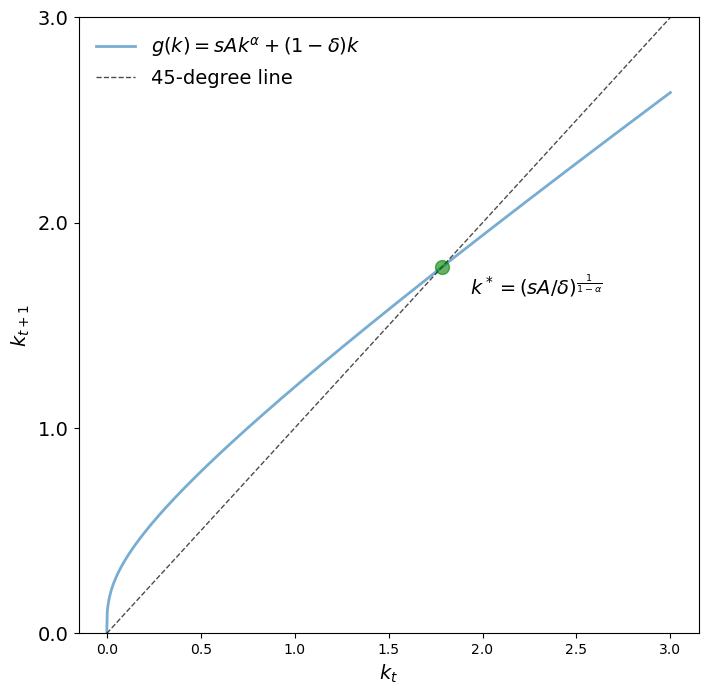

In [13]:
def plot_45(params, ax, fontsize=14):

    k_min, k_max = 0.0, 3.0
    k_grid = np.linspace(k_min, k_max, 1200)

    # Plot the functions
    lb = r"$g(k) = sAk^{\alpha} + (1 - \delta)k$"
    ax.plot(k_grid, g(k_grid, params), lw=2, alpha=0.6, label=lb)
    ax.plot(k_grid, k_grid, "k--", lw=1, alpha=0.7, label="45-degree line")

    # Show and annotate the fixed point
    kstar = exact_fixed_point(params)
    fps = (kstar,)
    ax.plot(fps, fps, "go", ms=10, alpha=0.6)
    ax.annotate(r"$k^* = (sA / \delta)^{\frac{1}{1-\alpha}}$",
                xy=(kstar, kstar),
                xycoords="data",
                xytext=(20, -20),
                textcoords="offset points",
                fontsize=fontsize)

    ax.legend(loc="upper left", frameon=False, fontsize=fontsize)

    ax.set_yticks((0, 1, 2, 3))
    ax.set_yticklabels((0.0, 1.0, 2.0, 3.0), fontsize=fontsize)
    ax.set_ylim(0, 3)
    ax.set_xlabel("$k_t$", fontsize=fontsize)
    ax.set_ylabel("$k_{t+1}$", fontsize=fontsize)


params = create_solow_params()
fig, ax = plt.subplots(figsize=(8, 8))
plot_45(params, ax)
plt.show()

### Exercise

Find $k^*$ using Newton's method, applied to $f(k)=g(k)-k$, whose derivative is $f'(k)=g'(k)-1$. Derive the derivative analytically and use the initial guess $x_0=0.8$.

In [14]:
def Dg(k, params):
    A, s, α, δ = params
    return α * A * s * k**(α - 1) + (1 - δ)

In [15]:
params = create_solow_params()
k_star_approx_newton = newton(f=lambda k: g(k, params) - k,
                              Df=lambda k: Dg(k, params) - 1,
                              x_0=0.8)

iteration 1, error = 0.08226
iteration 2, error = 0.00157
iteration 3, error = 0.00000
iteration 4, error = 0.00000


In [16]:
k_star_approx_newton - k_star

5.853095785823825e-13

Next, a quick demonstration of automatic differentiation with the `autograd` package. Run the installation cell below only if `autograd` is not already installed.

In [ ]:
%pip install autograd

In [17]:
from autograd import jacobian

In [18]:
jacobian_g = jacobian(g)
for k in np.linspace(0.1, 2.0, 5):
    print(f"k = {k}, jacobian_g(k, params) = {jacobian_g(k, params)}")

k = 0.1, jacobian_g(k, params) = 1.5021370205290898
k = 0.575, jacobian_g(k, params) = 0.8651581704676392
k = 1.05, jacobian_g(k, params) = 0.7739562335009837
k = 1.525, jacobian_g(k, params) = 0.7339626143785083
k = 2.0, jacobian_g(k, params) = 0.7108029972010425


In [19]:
k_star_approx_newton = newton(f=lambda x: g(x, params) - x,
                              Df=lambda x: jacobian_g(x, params) - 1,
                              x_0=0.8)

iteration 1, error = 0.08226
iteration 2, error = 0.00157
iteration 3, error = 0.00000
iteration 4, error = 0.00000


### Advantages and disadvantages of Newton's method

| **Aspect**               | **Advantage**                                                   | **Disadvantage**                                                  |
|--------------------------|-----------------------------------------------------------------|-------------------------------------------------------------------|
| **Speed**                | Quadratic convergence near the root.                            | Slow or divergent for poor initial guesses.                       |
| **Accuracy**             | Produces highly accurate results with few iterations.           | Requires accurate derivative calculations.                        |
| **Flexibility**          | Handles nonlinear and multidimensional problems.                | Computationally expensive for multidimensional problems.          |
| **Convergence**          | Fast convergence near a root with a good initial guess.         | No guarantee of global convergence; may fail in some cases.       |
| **Applicability**        | Suitable for smooth, differentiable functions.                  | Fails where the derivative is zero or undefined.                  |

### When to use Newton's method

- Newton's method is ideal when:
    - you have a good initial guess,
    - derivatives can be computed efficiently, and
    - high accuracy is needed and the function is smooth and well behaved.

- However, it may not be suitable for poorly behaved functions, functions with multiple roots, or problems with tight computational constraints.

- In such cases, alternatives such as **gradient descent**, **bisection**, or **quasi-Newton methods** (e.g., BFGS) may be preferable.

- Gradient descent is covered in the bonus Lecture 3c. See also [this QuantEcon lecture](https://jax.quantecon.org/autodiff.html) for an implementation.

- You may find it strange that gradient descent is used to solve an OLS problem. However, this is common practice among data scientists, and it can be more efficient, because matrix inversion is slow when there are many variables.

## Minimization: Finding the Extremum

### Unconstrained maximization

- Let's warm up with a simple optimization.

- Consider the following utility function with a bliss point; in other words, the utility function violates local non-satiation.

$$\max_{c,l}\; -[(c-c^*)^2+(l-l^*)^2], \qquad c^*=2,\quad l^*=4.$$

- `scipy.optimize` minimizes, so we minimize the negative of this objective.

In [20]:
# Objective function to minimize: the negative of the utility above
def obj_function(x, c_star, l_star):
    # x is a vector of length 2: x[0] = c, x[1] = l
    return (x[0] - c_star)**2 + (x[1] - l_star)**2


c_star, l_star = 2, 4
args = (c_star, l_star)
guess = np.ones(2)
result = opt.minimize(obj_function, x0=guess, args=args)
result

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 1.48373580637999e-14
        x: [ 2.000e+00  4.000e+00]
      nit: 2
      jac: [-1.900e-07  1.467e-07]
 hess_inv: [[ 9.500e-01 -1.500e-01]
            [-1.500e-01  5.500e-01]]
     nfev: 9
     njev: 3

Sometimes you will use a `lambda` function to make your code cleaner.

In [21]:
obj_short = lambda x: obj_function(x, c_star, l_star)

guess = np.zeros(2)
result = opt.minimize(obj_short, x0=guess)
result

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 9.095763293783874e-17
        x: [ 2.000e+00  4.000e+00]
      nit: 3
      jac: [ 6.371e-09 -2.159e-09]
 hess_inv: [[ 9.000e-01 -2.000e-01]
            [-2.000e-01  6.000e-01]]
     nfev: 12
     njev: 4

### Constrained maximization

- Now let's solve a constrained maximization problem:

$$\max_{x_1,x_2}\; x_1^{0.5}\, x_2^{0.5}$$

subject to the budget constraint

$$p_1x_1+p_2x_2\leq m,$$

where $p_1=2$, $p_2=1$, $m=10$.

- Note that the constraint is passed to `opt.minimize` as a dictionary.

In [22]:
# Parameters
p1, p2, m = 2, 1, 10
# eps is a small number that keeps x strictly positive
eps = 1e-8


# Objective function (negative, because scipy.optimize minimizes)
def utility(x):
    return -(x[0]**0.5 * x[1]**0.5)


# Budget constraint, written so that it must be greater than or equal to zero
def budget_constraint(x):
    return m - (p1 * x[0] + p2 * x[1])


# Bounds for x1 and x2 (non-negative)
bounds = [(eps, None), (eps, None)]

# Constraints in dictionary form
constraints = {'type': 'ineq', 'fun': budget_constraint}

# Initial guess
x0 = [1, 1]

# Solve the optimization problem
result = opt.minimize(utility, x0, bounds=bounds, constraints=constraints)

# Display results
print("Optimal values of x1 and x2:", result.x)
print("Maximum utility:", -result.fun)

Optimal values of x1 and x2: [2.50005924 4.99988152]
Maximum utility: 3.5355339049401806


Because utility is increasing in both goods, the budget constraint binds at the optimum. We can therefore also impose it as an equality (`'type': 'eq'`). This version also shows how to pass parameters to the constraint through default arguments.

In [23]:
# Budget constraint with the parameters as default arguments
def budget_constraint(x, m=m, p1=p1, p2=p2):
    return m - (p1 * x[0] + p2 * x[1])


# Equality constraint in dictionary form
constraints = {'type': 'eq', 'fun': budget_constraint}

result = opt.minimize(utility, x0, bounds=bounds, constraints=constraints)
result

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: -3.5355337811482928
       x: [ 2.501e+00  4.999e+00]
     nit: 6
     jac: [-7.069e-01 -3.536e-01]
    nfev: 18
    njev: 6

### Algorithms

- It is important to understand which method suits the properties of your problem.

- I want to highlight simplex-based methods and gradient-based methods.

- Note that a more sophisticated method is not always better, even setting speed aside.

- Watch these visualizations to understand how a [simplex-based method](https://www.youtube.com/watch?v=XfdHAcHat7M) and a [gradient-based method](https://www.youtube.com/watch?v=VIoWzHlz7k8&t=71s) work.

| Feature                    | Nelder-Mead            | BFGS                     | SLSQP                     |
|----------------------------|------------------------|--------------------------|---------------------------|
| **Type**                  | Derivative-free       | Gradient-based          | Gradient-based, constrained |
| **Handles Constraints?**  | No                    | No                      | Yes                      |
| **Gradient Required?**    | No                    | Yes (finite differences if not supplied) | Yes (finite differences if not supplied) |
| **Speed**                 | Slow                  | Fast (for unconstrained) | Moderate                 |
| **Robustness**            | High (small problems) | High (smooth problems)  | High (with constraints)  |
| **Scalability**           | Poor (high dimensions)| Moderate (medium scale) | Moderate (with constraints) |
| **Use Case**              | Noisy, non-smooth     | Smooth, unconstrained   | Constrained optimization |

- To see why this matters, try to find a method that solves each of the following problems. The problems come from [this estimagic exercise](https://github.com/optimagic-dev/scipy-estimagic/blob/main/exercises/03_play_with_algorithm_and_algo_options.ipynb).

**Problem 1: Powell's function with steps.** Rounding `x` makes the criterion a step function.

In [24]:
your_method = "Nelder-Mead"  # or "Powell", "L-BFGS-B", etc.


# Powell's function with steps
def powell_steps(x):
    x = x.round(4)
    fvec = np.zeros(4)
    fvec[0] = x[0] + 10 * x[1]
    fvec[1] = np.sqrt(5.0) * (x[2] - x[3])
    fvec[2] = (x[1] - 2 * x[2]) ** 2
    fvec[3] = np.sqrt(10.0) * (x[0] - x[3]) ** 2
    return {"root_contributions": fvec, "value": fvec @ fvec}


# Wrapper for scipy.optimize.minimize
def objective_function(x):
    return powell_steps(x)["value"]


# Initial guess
powell_start = np.array([3, -1, 0, 1])

# Minimize with the chosen method
res_powell = opt.minimize(objective_function, powell_start, method=your_method)

# Display the result
print("Optimal parameters:", res_powell.x)
print("Optimal value of the criterion:", res_powell.fun)
res_powell

Optimal parameters: [ 0.00808801 -0.00075581  0.01664224  0.01661975]
Optimal value of the criterion: 1.398536625e-06


       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 1.398536625e-06
             x: [ 8.088e-03 -7.558e-04  1.664e-02  1.662e-02]
           nit: 157
          nfev: 286
 final_simplex: (array([[ 8.088e-03, -7.558e-04,  1.664e-02,  1.662e-02],
                       [ 8.102e-03, -7.573e-04,  1.664e-02,  1.662e-02],
                       ...,
                       [ 8.151e-03, -7.623e-04,  1.664e-02,  1.662e-02],
                       [ 8.156e-03, -7.631e-04,  1.664e-02,  1.662e-02]]), array([ 1.399e-06,  1.399e-06,  1.399e-06,  1.426e-06,
                        1.426e-06]))

**Problem 2: the Bratu problem.**

In [25]:
def bratu(x):
    alpha = 4.0
    # Reshape x into a square matrix
    x = x.reshape((int(np.sqrt(len(x))), int(np.sqrt(len(x)))))
    p = x.shape[0] + 2
    h = 1 / (p - 1)
    c = h**2 * alpha

    # Create a padded array for the calculations
    xvec = np.zeros((x.shape[0] + 2, x.shape[1] + 2))
    xvec[1 : x.shape[0] + 1, 1 : x.shape[1] + 1] = x

    # Compute the contributions and flatten the result
    fvec = np.zeros_like(x)
    for i in range(2, p):
        for j in range(2, p):
            fvec[i - 2, j - 2] = (
                4 * xvec[i - 1, j - 1]
                - xvec[i, j - 1]
                - xvec[i - 2, j - 1]
                - xvec[i - 1, j]
                - xvec[i - 1, j - 2]
                - c * np.exp(xvec[i - 1, j - 1])
            )

    # Return the value to minimize and additional details
    fvec = fvec.flatten()
    return {"root_contributions": fvec, "value": fvec @ fvec}

In [26]:
your_method = "BFGS"


# Wrapper for scipy.optimize.minimize
def objective_function(x):
    return bratu(x)["value"]


# Initial guess: an 8x8 grid, flattened
bratu_start = np.zeros(64)

res_bratu = opt.minimize(
    objective_function,
    bratu_start,
    method=your_method,
    # Maximum function evaluations (used by derivative-free methods;
    # BFGS ignores it with a warning)
    options={"maxfev": 5000}
)

# Display results
print("Optimization Success:", res_bratu.success)
print("Optimal Parameters (flattened):", res_bratu.x)
print("Optimal Value of the Criterion:", res_bratu.fun)
res_bratu

<ipython-input>:12: OptimizeWarning: Unknown solver options: maxfev
  res_bratu = opt.minimize(


Optimization Success: True
Optimal Parameters (flattened): [0.07234547 0.11814714 0.14591605 0.1591421  0.15914204 0.14591595
 0.11814701 0.07234546 0.11814704 0.19875125 0.24923497 0.2736096
 0.27360962 0.24923506 0.1987513  0.11814717 0.14591637 0.24923553
 0.3153041  0.34752932 0.34752935 0.31530415 0.24923551 0.14591643
 0.15914274 0.27361047 0.34752982 0.38377114 0.38377115 0.34752978
 0.2736104  0.15914271 0.15914276 0.27361033 0.34752975 0.38377123
 0.38377122 0.34752972 0.2736103  0.15914271 0.14591659 0.24923542
 0.31530406 0.34752939 0.34752939 0.31530408 0.24923546 0.14591654
 0.11814728 0.19875121 0.24923505 0.2736096  0.27360956 0.24923505
 0.19875126 0.11814722 0.07234538 0.11814688 0.14591604 0.15914213
 0.15914211 0.14591609 0.11814699 0.0723454 ]
Optimal Value of the Criterion: 4.0462041848638845e-11


  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 4.0462041848638845e-11
        x: [ 7.235e-02  1.181e-01 ...  1.181e-01  7.235e-02]
      nit: 62
      jac: [ 1.267e-06  3.116e-06 ... -1.204e-06 -1.046e-06]
 hess_inv: [[ 2.668e-01  1.644e-01 ... -6.764e-02 -1.790e-01]
            [ 1.644e-01  3.331e-01 ... -6.468e-02 -6.786e-02]
            ...
            [-6.764e-02 -6.468e-02 ...  3.340e-01  1.647e-01]
            [-1.790e-01 -6.786e-02 ...  1.647e-01  2.671e-01]]
     nfev: 5525
     njev: 85

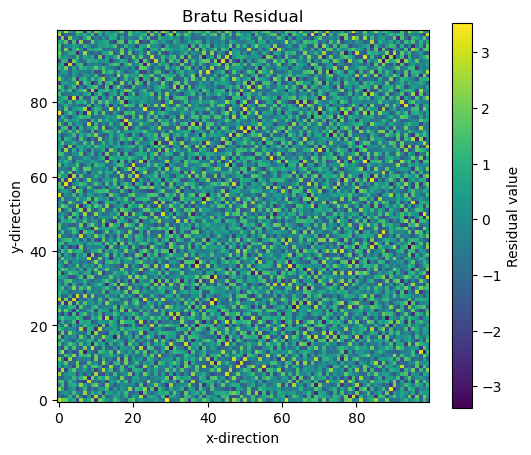

In [27]:
# It is helpful to visualize the residual

def visualize_bratu(x):
    """
    Visualize the Bratu residual on a 2D grid.

    Parameters
    ----------
    x : np.ndarray
        A 1D array that can be reshaped into an n x n grid,
        representing values of the Bratu problem on that grid.
    """

    # Compute the residual and the overall value
    result = bratu(x)

    # Extract the 1D residual array
    fvec = result["root_contributions"]

    # Reshape the residual into the same 2D shape used internally
    n = int(np.sqrt(len(fvec)))
    fmat = fvec.reshape((n, n))

    # Plot the 2D residual as a heatmap
    plt.figure(figsize=(6, 5))
    im = plt.imshow(fmat, origin="lower", cmap="viridis")
    plt.colorbar(im, label="Residual value")
    plt.title("Bratu Residual")
    plt.xlabel("x-direction")
    plt.ylabel("y-direction")
    plt.show()


# Example usage: x must have length n*n so that it can be reshaped
# into an (n, n) matrix. Here, a random guess with n = 100.
n = 100
x_init = np.random.rand(n * n)

visualize_bratu(x_init)

Selecting the right algorithm is a rabbit hole. While this course focuses on applications, I recommend [Ken Judd's lectures](https://kenjudd.org/teaching/numerical-methods-by-judd/) to those interested in graduate study; some lecture videos are also available on YouTube. A cheat sheet is available [here](https://estimagic.org/en/latest/how_to/how_to_algorithm_selection.html).

### Local vs. global minimization

- So far, we have dealt only with local minimization.

- When the objective is not well behaved, we may get stuck at a local minimum. This is typical in calibration or the simulated method of moments.

- A simple solution is a multistart: run a local minimization algorithm from many starting points. This is what I always do at the first stage.

- Multistart is easy to parallelize.

- If this is a concern, we can also use algorithms that target global minimization. There are some options in [SciPy](https://docs.scipy.org/doc/scipy/reference/optimize.html).
    - An obvious one is `brute` (grid search), but it becomes infeasible as the number of dimensions grows.
    - Unfortunately, global algorithms are typically slow; luckily, most of them are easy to parallelize.

- In practice, we may use different algorithms along different dimensions.